# B(T=30) 꼬리 진단 결과


**결론: 큰 SFR의 과소예측은 꼬리 회귀기와 꼬리 확률 양쪽에서 발생한다. 0/양수 분류의 영향은 작다.**

저장소 `ZizonK7/sdi2026-galaxy-sfr`, main 커밋 `fef00ffaf2992104c8d6dc0e87ab0b30275d8c9d`의 `work/팀원/james_tail.ipynb`에서 모델 클래스를 그대로 가져왔다. 데이터의 Git blob SHA까지 원본과 일치한다. 원래 80:20 분할의 학습 166,749개만 사용해 동일한 5-fold OOF 예측을 생성했다. 검증셋을 평가하거나 모델을 변경하지 않았다.

기존 2단계 OOF RMSE **9.126032**, B(T=30) **8.798251**로 저장된 결과가 소수점 셋째 자리까지 재현됐다.


이 노트북은 저장된 OOF를 읽어 수치를 재계산합니다. 학습 재현은 `run_diagnosis.py`를 사용하세요.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import json
root=Path('.')
z=np.load(root/'oof_components.npz')
y=z['actual']; p=z['p_positive']; q=z['p_tail_given_positive']
et=z['e_tail']; em=z['e_mid']; pred=z['prediction']
print(json.dumps(json.loads((root/'metadata.json').read_text()),ensure_ascii=False,indent=2))


{
  "repository": "ZizonK7/sdi2026-galaxy-sfr",
  "commit": "fef00ffaf2992104c8d6dc0e87ab0b30275d8c9d",
  "data_git_blob_sha": "06479cedd323253f08af9983c73f395cc02d3774",
  "train_n": 166749,
  "holdout_evaluated": false,
  "threshold": 30,
  "seed": 42,
  "cv": "KFold(5, shuffle=True, random_state=42) on original training split",
  "features": [
    "log10_halo_mass",
    "log10_stellar_mass",
    "log10_BH_mass",
    "log10_main_prog_mass",
    "log10_main_prog_stellar_mass",
    "log10_mass_ratio",
    "log10_overdensity_plus_1",
    "pos_x",
    "pos_y",
    "pos_z",
    "vel_x",
    "vel_y",
    "vel_z"
  ],
  "model_source": "Exact class definitions from james_tail.ipynb cells 3 and 14",
  "python": "3.12.14",
  "numpy": "2.5.4",
  "pandas": "2.2.3",
  "scipy": "1.18.1",
  "sklearn": "1.9.1",
  "matplotlib": "3.11.2",
  "threads": 4,
  "elapsed_seconds": 50.711668968200684,
  "B_oof_rmse": 8.798250536759287,
  "two_stage_oof_rmse": 9.126031716958476,
  "expected_saved_B_rounded":

In [2]:
parts=pd.DataFrame({'y':y,'prediction':pred,'e_tail':et,'p_positive':p,'p_tail':q,
 'regression_gap':y-et,'positive_gate_drop':(1-p)*et,'tail_gate_drop':p*(1-q)*(et-em)})
assert np.allclose(y-pred, parts[['regression_gap','positive_gate_drop','tail_gate_drop']].sum(axis=1))
for label,mask in [('100<SFR<=300',(y>100)&(y<=300)),('SFR>300',y>300),('SFR>100',y>100)]:
 print(label,'n=',int(mask.sum()))
 print(parts.loc[mask].mean().round(4).to_string())
 print('p_tail < 0.5:',int((q[mask]<.5).sum()))


100<SFR<=300 n= 181
y                     145.6627
prediction             85.4955
e_tail                127.7635
p_positive              0.9914
p_tail                  0.7350
regression_gap         17.8992
positive_gate_drop      0.9765
tail_gate_drop         41.2915
p_tail < 0.5: 53
SFR>300 n= 28
y                     531.0550
prediction             92.6975
e_tail                221.2576
p_positive              0.9938
p_tail                  0.4302
regression_gap        309.7974
positive_gate_drop      0.9939
tail_gate_drop        127.5662
p_tail < 0.5: 19
SFR>100 n= 209
y                     197.2942
prediction             86.4604
e_tail                140.2890
p_positive              0.9918
p_tail                  0.6941
regression_gap         57.0052
positive_gate_drop      0.9788
tail_gate_drop         52.8499
p_tail < 0.5: 72


In [3]:
p_oracle_tail=p*np.where(y>30,et,em)
p_oracle_positive=(y>0)*(q*et+(1-q)*em)
for name,a in [('Actual B',pred),('ORACLE tail membership (diagnostic only)',p_oracle_tail),('ORACLE positive membership (diagnostic only)',p_oracle_positive)]:
 print(name, float(np.sqrt(np.mean((y-a)**2))))


Actual B 8.798250536759287
ORACLE tail membership (diagnostic only) 7.667558621268792
ORACLE positive membership (diagnostic only) 8.786905802461325


정답 구간을 사용한 비교는 진단 전용이며 실제 성능이나 달성 가능한 경계가 아닙니다.



1. 꼬리 분류 AUC가 전체 양수 집단에서 약 0.996이어도 극단 SFR에서 확률이 적절하다는 뜻은 아니다. 먼저 큰 SFR인데 낮은 꼬리 확률을 받은 행을 분석한다.
2. 100~300 구간에는 꼬리 분류/확률 개선을 우선 검토하고, 300 초과에는 회귀기 개선을 병행한다. 확률을 일괄적으로 높이는 것은 보통 은하의 과대예측을 늘릴 수 있다.
3. SFR>300은 28개뿐이고 전체 B 오차제곱합의 약 72.85%를 차지한다. 다음 후보도 전체 OOF RMSE와 구간별 부작용을 함께 비교해야 한다.





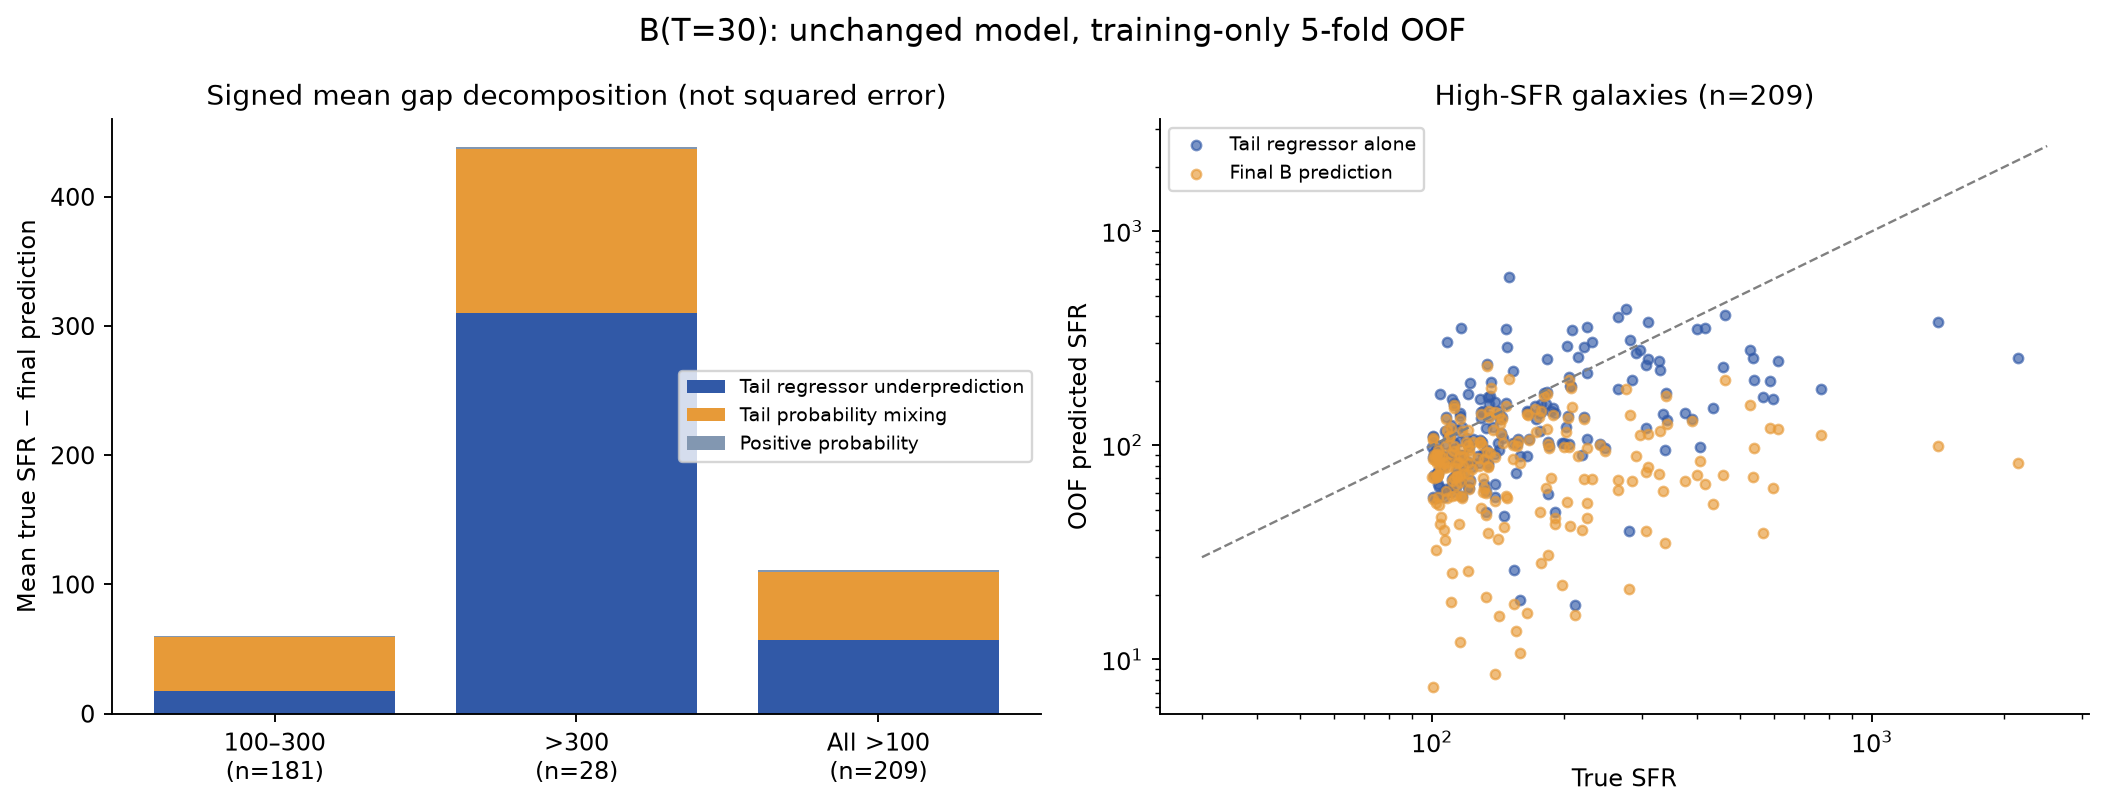

In [4]:
from IPython.display import Image, display
display(Image(filename="diagnosis.png"))
